In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)

torch.Size([1, 28, 28])


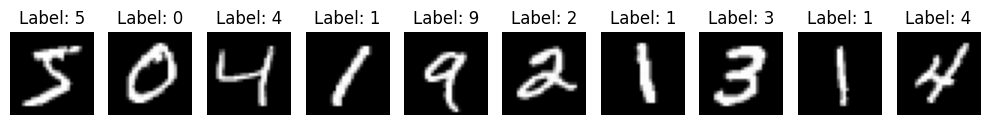

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from quantizer import VectorQuantizer
from vqvae import VQVAE


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # (28x28) → (14x14)
            nn.ReLU(),
            nn.Conv2d(16, 64, kernel_size=4, stride=2, padding=1),  # (14x14) → (7x7)
            nn.ReLU(),
            nn.Conv2d(64, 16, kernel_size=4, stride=2, padding=1),  # (7x7) → (3x3)
        )

    def forward(self, x):
        return self.encoder(x)  # (B, 16, 3, 3)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(16, 64, kernel_size=4, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid() # 输出范围控制在 [0,1]，适合图像重建
        )

    def forward(self, x):
        return self.decoder(x)  # (B, 1, 28, 28)

In [4]:
quantizer = VectorQuantizer(n_e=128, e_dim=9)
vqvae = VQVAE(Encoder(), Decoder(), quantizer)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x_q, indices, vq_loss, codebook_usage = vqvae(x) 
print(x_q.shape)
print(indices.shape) # use 16 tokens to encode one image
print(codebook_usage.shape)

z_q = vqvae.encode(x)
print(z_q.shape)



torch.Size([1, 1, 28, 28])
torch.Size([1, 16])
torch.Size([128])
torch.Size([1, 16, 3, 3])


In [5]:
quantizer = VectorQuantizer(n_e=128, e_dim=9)
vqvae = VQVAE(Encoder(), Decoder(), quantizer)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=512, shuffle=True, num_workers=4)
optimizer = torch.optim.Adam(vqvae.parameters(), lr=1e-3)
epochs = 30

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


vqvae.to(device).train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_q, _, q_loss, _ = vqvae(img)
        loss = F.mse_loss(x_q, img) + q_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")



Epoch 1/30, Loss: 0.0784
Epoch 5/30, Loss: 0.0360
Epoch 10/30, Loss: 0.0322
Epoch 15/30, Loss: 0.0305
Epoch 20/30, Loss: 0.0287
Epoch 25/30, Loss: 0.0262
Epoch 30/30, Loss: 0.0264


[[ 76  19  89  45 101  98  52  43 123  79  80  30  78  67  39  38]
 [ 62   0  10  11  99  61  70  27  88 104  64  30 121  26  35  53]
 [125  31 122  11  34  98  52  67 127 104  55  29  59  37  39  77]
 [125  74  79 102 108  48  90  96  36  50   5  30  23 112  72  38]
 [125 101   3  52 101 123  82  69  66 127  80  29  91  15 110  38]
 [125  31  83  54  99  61  52  37   8 104  60  29 121  37  39  77]
 [118  19  94  40   2   1  56  68 123 116  55  29 127 109  12   6]
 [125   2  88  41  99  48  70  70 117  26  60  29  18  60  22   3]
 [125  74   9  46 105  10  46  43  53  81  55  29  71 112  72  32]
 [125  96  89 102 101   1  70 124  59   4  55  30  36 112  39  32]]


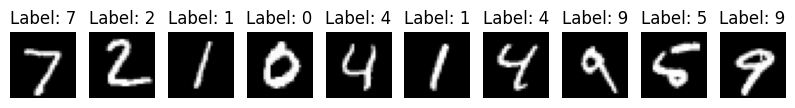

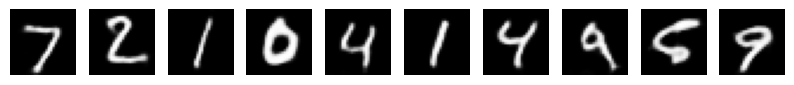

In [6]:
# 遍历前10张图片
x = torch.vstack([test_data[i][0] for i in range(10)]).unsqueeze(1).to(device)
x_q, ids, vq_loss, _ = vqvae(x)
x_q = x_q.cpu().detach()
x_p = vqvae.decode(vqvae.encode(x)).cpu().detach()

print(ids.cpu().numpy())

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = x_p[i], test_data[i][1]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.axis('off')  # 关闭坐标轴

2.8367751e-05


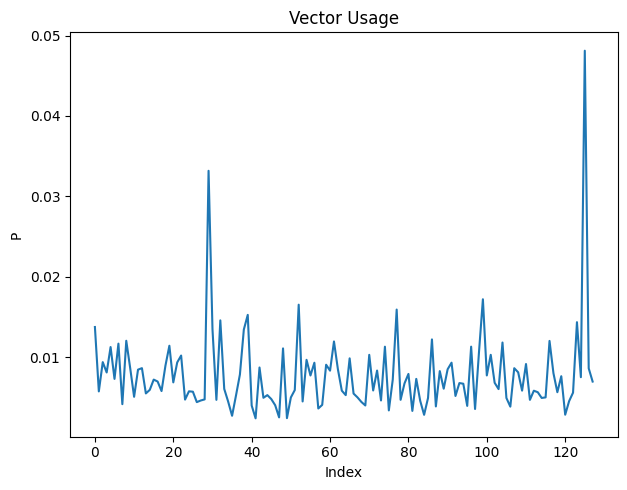

In [7]:
test_loader = torch.utils.data.DataLoader(test_data, batch_size=512, shuffle=False, num_workers=4)

vqvae.eval()
usage = 0
with torch.inference_mode():
    for img, _ in test_loader:
        img = img.to(device)

        _, _, _, u = vqvae(img)
        usage += u.cpu().numpy() * len(img)

usage /= len(test_data)

print(usage.var())
plt.figure(figsize=(12, 5))

# 折线图
plt.subplot(1, 2, 1)
plt.plot(usage)
plt.title('Vector Usage')
plt.xlabel('Index')
plt.ylabel('P')


plt.tight_layout()
plt.show()

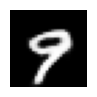

In [8]:
with torch.inference_mode():
    code = torch.tensor([[125, 96, 89, 102, 101, 1, 70, 124, 59, 4, 55, 30, 36, 112, 39, 32]], device=device)
    img = vqvae.decode_code(code, shape=(16, 3, 3))

plt.figure(figsize=(1, 1))
plt.imshow(img.squeeze().cpu().numpy(), cmap='gray')
plt.axis('off')
plt.show()